# 06 — Transformer (self-attention)

**Input:** `../data/processed/raddar.npz`, shared code `../src/dl_utils.py`, previous results `../results/dl_results_all.csv`
**Output:** results in `../results/`, figures in `../figures/`

**Why a Transformer?** The LSTM reads the map one step at a time and must carry everything in its memory. A Transformer uses **self-attention**: every token (here, a column or a row of the map) looks **directly at all the other tokens at once** and decides which ones are relevant to it. There is no sequential reading and no fading memory.

**Tokens.** As for the RNN, the map is cut into a sequence of tokens:
| Tokens | Number of tokens | One token = |
|---|---|---|
| **Doppler columns** | 61 | the 11 range bins at one velocity |
| **Range rows** | 11 | the 61 Doppler bins at one distance |

**The architecture follows the course notebook** (`MLLB_Text_Classification_Transformer`): a `TransformerBlock` layer (multi-head attention + feed-forward network, with residual connections, layer normalisation and dropout), adapted to radar maps: the tokens are projected by a Dense layer instead of a word embedding.

**Experiments (3 seeds each)**
| Exp. | Tokens | Input | Question |
|---|---|---|---|
| A | Doppler columns | full map | reference Transformer |
| B | range rows | full map | which tokenisation works better? |
| C | Doppler columns | cropped map | stripe shortcut test |
| D | Doppler columns | full map, **no positional encoding** | does the order of the tokens matter? |

**Hypotheses:** the Transformer is competitive with the RNN but not with the CNN — with only ~12,600 training maps, Transformers usually lack the data they need (they have fewer built-in assumptions than a CNN). Without positional encoding, attention cannot know where a column is in the map, so performance should drop.

In [1]:
import sys, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append("../src")
from dl_utils import load_data, crop_center, normalise, evaluate, plot_history, plot_confusion, CENTER_DOPPLER

import keras
from keras import layers, ops

SEEDS = [42, 7, 2026]
FIG = Path("../figures"); FIG.mkdir(parents=True, exist_ok=True)
RES = Path("../results"); RES.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

D = load_data()
X, y, CLASSES = D["X"], D["y"], D["class_names"]
tr, va, te = D["train"], D["val"], D["test"]
Xn = normalise(X, tr)
Xc = normalise(crop_center(X), tr)
TOKENS = {
    "full, Doppler columns": Xn.transpose(0, 2, 1),    # 61 tokens of 11 values
    "full, range rows": Xn,                            # 11 tokens of 61 values
    "cropped, Doppler columns": Xc.transpose(0, 2, 1), # 13 tokens of 11 values
}
for k, v in TOKENS.items():
    print(f"{k:26s} -> {v.shape[1]} tokens of {v.shape[2]} values")

I0000 00:00:1794482765.701001     507 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794482765.751282     507 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1794482766.741251     507 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


full, Doppler columns      -> 61 tokens of 11 values
full, range rows           -> 11 tokens of 61 values
cropped, Doppler columns   -> 13 tokens of 11 values


## 1. Building blocks
**Token + position embedding.** Each token (11 or 61 values) is projected by a Dense layer into a vector of size 32. A **learned position vector** is added, so the model knows where each token comes from (which velocity or which distance). Without it, self-attention would treat the map as an unordered *set* of columns.

**Transformer block** (as in the course notebook):
```
x ──► Multi-Head Self-Attention (4 heads) ──► Dropout ──► + x ──► LayerNorm ──► Feed-forward (Dense 64 → Dense 32) ──► Dropout ──► + ──► LayerNorm
```
- **Self-attention:** each token is projected into a Query, a Key and a Value; the attention weights are softmax(Q·Kᵀ/√d), and each output is the weighted sum of the Values. A token can therefore gather information from any other token in one step.
- **Multi-head:** 4 attentions in parallel, each free to learn a different kind of relation.
- **Residual connections (+ x)** and **layer normalisation** keep training stable when blocks are stacked.

**Classifier:** 2 Transformer blocks → average over all tokens (GlobalAveragePooling1D) → Dropout → Dense(64) → Dropout → Dense(3, softmax).

In [2]:
class TokenAndPositionEmbedding(layers.Layer):
    def __init__(self, maxlen, embed_dim, use_position=True, **kw):
        super().__init__(**kw)
        self.proj = layers.Dense(embed_dim)                       # continuous values instead of words
        self.pos = layers.Embedding(input_dim=maxlen, output_dim=embed_dim) if use_position else None
        self.maxlen, self.use_position = maxlen, use_position

    def call(self, x):
        x = self.proj(x)
        if self.use_position:
            x = x + self.pos(ops.arange(self.maxlen))
        return x


class TransformerBlock(layers.Layer):
    def __init__(self, embed_dim, num_heads, ff_dim, rate=0.1, return_scores=False, **kw):
        super().__init__(**kw)
        self.att = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim)
        self.ffn = keras.Sequential([layers.Dense(ff_dim, activation="relu"), layers.Dense(embed_dim)])
        self.norm1 = layers.LayerNormalization(epsilon=1e-6)
        self.norm2 = layers.LayerNormalization(epsilon=1e-6)
        self.drop1, self.drop2 = layers.Dropout(rate), layers.Dropout(rate)
        self.return_scores = return_scores

    def call(self, x, training=False):
        attn, scores = self.att(x, x, return_attention_scores=True, training=training)
        x = self.norm1(x + self.drop1(attn, training=training))
        x = self.norm2(x + self.drop2(self.ffn(x), training=training))
        return (x, scores) if self.return_scores else x


def build_transformer(input_shape, embed_dim=32, num_heads=4, ff_dim=64, n_blocks=2,
                      use_position=True, dropout=0.3, n_classes=3):
    inp = keras.Input(input_shape)
    x = TokenAndPositionEmbedding(input_shape[0], embed_dim, use_position, name="embedding")(inp)
    x, scores = TransformerBlock(embed_dim, num_heads, ff_dim, return_scores=True, name="block1")(x)
    for i in range(1, n_blocks):
        x = TransformerBlock(embed_dim, num_heads, ff_dim, name=f"block{i + 1}")(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(64, activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    out = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inp, out, name="transformer")
    model.attention_model = keras.Model(inp, scores)      # to inspect the attention weights later
    return model

def train(model, Xi, seed, epochs=100):
    keras.utils.set_random_seed(seed)
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
    t0 = time.time()
    h = model.fit(Xi[tr], y[tr], validation_data=(Xi[va], y[va]), epochs=epochs, batch_size=128,
                  callbacks=[stop], verbose=0)
    return h, time.time() - t0

build_transformer(TOKENS["full, Doppler columns"].shape[1:]).summary()

Model: "transformer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 61, 11)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding                       │ (None, 61, 32)         │         2,336 │
│ (TokenAndPositionEmbedding)     │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1 (TransformerBlock)       │ [(None, 61, 32),       │        21,120 │
│                                 │ (None, 4, 61, 61)]     │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2 (TransformerBlock)       │ (None, 61, 32)         │        21,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,883 (183.14 KB)

 Trainable params: 46,883 (183.14 KB)

 Non-trainable params: 0 (0.00 B)

## 2. Training: 4 experiments × 3 seeds

In [3]:
EXPERIMENTS = [
    ("Transformer", "full, Doppler columns", True),
    ("Transformer", "full, range rows", True),
    ("Transformer", "cropped, Doppler columns", True),
    ("Transformer (no positional encoding)", "full, Doppler columns", False),
]
runs, histories, preds, models = [], {}, {}, {}
for name, inp, use_pos in EXPERIMENTS:
    Xi = TOKENS[inp]
    for s in SEEDS:
        keras.utils.set_random_seed(s)
        model = build_transformer(Xi.shape[1:], use_position=use_pos)
        h, t = train(model, Xi, s)
        pv = model.predict(Xi[va], verbose=0).argmax(1)
        pt = model.predict(Xi[te], verbose=0).argmax(1)
        r = {"Model": name, "Input": inp, "Seed": s, "Epochs": len(h.history["loss"]),
             "Best epoch": int(np.argmin(h.history["val_loss"])) + 1, "Time (s)": t,
             "Params": model.count_params(), "Val accuracy": (pv == y[va]).mean()}
        r.update({("Test " + k): v for k, v in evaluate(y[te], pt, CLASSES).items()})
        runs.append(r)
        if s == SEEDS[0]:
            histories[(name, inp)], preds[(name, inp)], models[(name, inp)] = h, pt, model
        print(f"{name:37s} | {inp:25s} | seed {s:4d} | test acc {r['Test accuracy']:.3f} | {t:5.0f} s")

runs = pd.DataFrame(runs)
runs.to_csv(RES / "dl_step6_transformer_runs.csv", index=False)

Transformer                           | full, Doppler columns     | seed   42 | test acc 0.926 |   137 s


Transformer                           | full, Doppler columns     | seed    7 | test acc 0.933 |   139 s


Transformer                           | full, Doppler columns     | seed 2026 | test acc 0.946 |   174 s


Transformer                           | full, range rows          | seed   42 | test acc 0.928 |    46 s


Transformer                           | full, range rows          | seed    7 | test acc 0.926 |    46 s


Transformer                           | full, range rows          | seed 2026 | test acc 0.914 |    37 s


... (2 outputs left out)

Transformer                           | cropped, Doppler columns  | seed 2026 | test acc 0.925 |    45 s


Transformer (no positional encoding)  | full, Doppler columns     | seed   42 | test acc 0.935 |   230 s


Transformer (no positional encoding)  | full, Doppler columns     | seed    7 | test acc 0.943 |   226 s


Transformer (no positional encoding)  | full, Doppler columns     | seed 2026 | test acc 0.931 |   180 s


In [4]:
cols = ["Val accuracy", "Test accuracy"] + [f"Test recall {c}" for c in CLASSES]
agg = runs.groupby(["Model", "Input"], sort=False)
summary = agg[cols].mean()
summary["Test accuracy std (3 seeds)"] = agg["Test accuracy"].std()
summary["Params"] = agg["Params"].first()
summary["Mean time per run (s)"] = agg["Time (s)"].mean()
summary.round(3)

Val accuracy  \
Model                                Input                                    
Transformer                          full, Doppler columns            0.957   
                                     full, range rows                 0.941   
                                     cropped, Doppler columns         0.939   
Transformer (no positional encoding) full, Doppler columns            0.962   

                                                               Test accuracy  \
Model                                Input                                     
Transformer                          full, Doppler columns             0.935   
                                     full, range rows                  0.923   
                                     cropped, Doppler columns          0.924   
Transformer (no positional encoding) full, Doppler columns             0.936   

                                                               Test recall Cars  \
Model                                Input                                        
Transformer                          full, Doppler columns                0.906   
                                     full, range rows                     0.886   
                                     cropped, Doppler columns             0.872   
Transformer (no positional encoding) full, Doppler columns                0.897   

                                                               Test recall Drones  \
Model                                Input                                          
Transformer                          full, Doppler columns                  0.910   
                                     full, range rows                       0.916   
                                     cropped, Doppler columns               0.924   
Transformer (no positional encoding) full, Doppler columns                  0.922   

                                                               Test recall People  \
Model                                Input                                          
Transformer                          full, Doppler columns                  0.979   
                                     full, range rows                       0.960   
                                     cropped, Doppler columns               0.969   
Transformer (no positional encoding) full, Doppler columns                  0.982   

                                                               Test accuracy std (3 seeds)  \
Model                                Input                                                   
Transformer                          full, Doppler columns                           0.010   
                                     full, range rows                                0.008   
                                     cropped, Doppler columns                        0.002   
Transformer (no positional encoding) full, Doppler columns                           0.006   

                                                               Params  \
Model                                Input                              
Transformer                          full, Doppler columns      46883   
                                     full, range rows           46883   
                                     cropped, Doppler columns   45347   
Transformer (no positional encoding) full, Doppler columns      44931   

                                                               Mean time per run (s)  
Model                                Input                                            
Transformer                          full, Doppler columns                   149.894  
                                     full, range rows                         43.084  
                                     cropped, Doppler columns                 48.999  
Transformer (no positional encoding) full, Doppler columns                   211.844

## 3. Learning curves (seed 42)

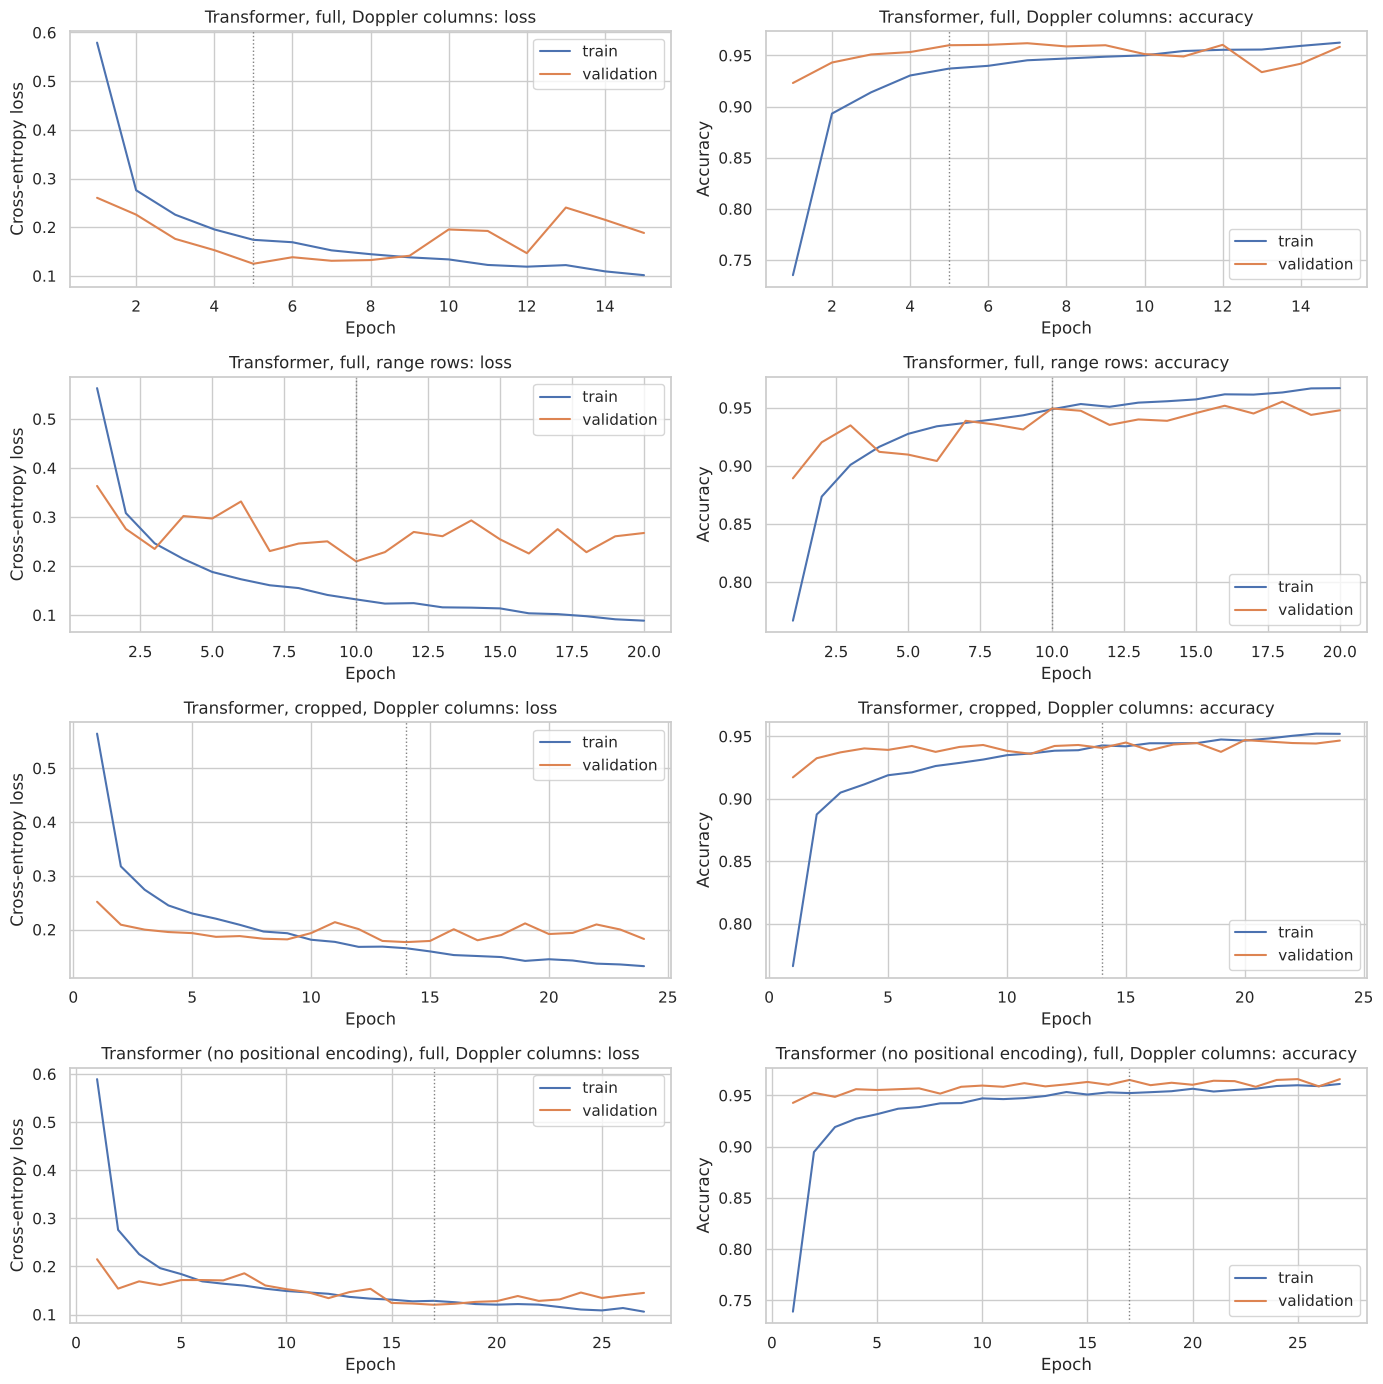

In [5]:
keys = [(n, i) for n, i, _ in EXPERIMENTS]
fig, axes = plt.subplots(4, 2, figsize=(14, 14))
for row, key in enumerate(keys):
    plot_history(histories[key], f"{key[0]}, {key[1]}", axes[row, 0], axes[row, 1])
plt.tight_layout(); plt.savefig(FIG / "dl_21_transformer_learning_curves.png", dpi=200); plt.show()

## 4. Comparison with all previous models (test sessions)

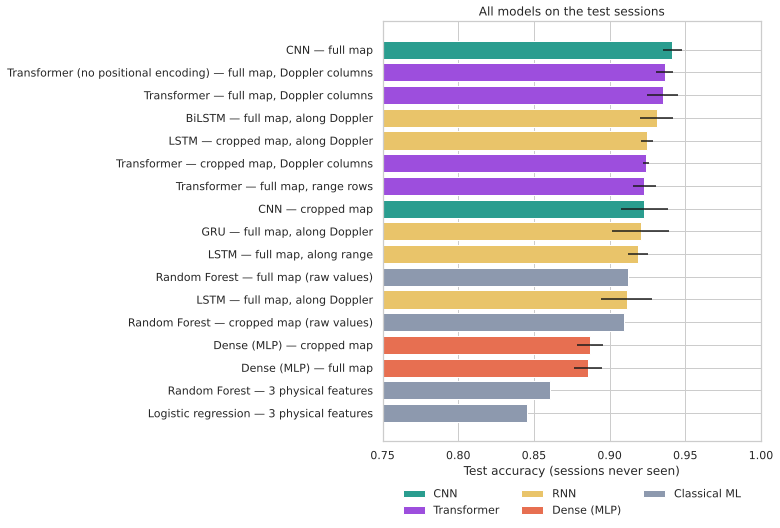

,Model,Input,Val accuracy,Test accuracy,Test recall Cars,Test recall Drones,Test recall People,Test accuracy std (3 seeds),Params
0,Logistic regression,3 physical features,0.916,0.845,0.681,0.899,0.947,NaN,NaN
1,Random Forest,3 physical features,0.916,0.861,0.759,0.842,0.962,NaN,NaN
2,Random Forest,full map (raw values),0.917,0.912,0.849,0.960,0.930,NaN,NaN
3,Random Forest,cropped map (raw values),0.918,0.909,0.837,0.954,0.938,NaN,NaN
4,Dense (MLP),full map,0.927,0.886,0.824,0.911,0.920,0.009,205315.0
5,Dense (MLP),cropped map,0.921,0.887,0.798,0.908,0.948,0.008,70147.0
6,CNN,full map,0.945,0.941,0.938,0.898,0.977,0.006,60739.0
7,CNN,cropped map,0.938,0.923,0.822,0.965,0.978,0.015,60739.0
8,LSTM,"full map, along Doppler",0.925,0.911,0.887,0.926,0.921,0.017,23811.0
9,LSTM,"full map, along range",0.915,0.919,0.905,0.897,0.947,0.007,36611.0


In [6]:
prev = pd.read_csv(RES / "dl_results_all.csv")
prev = prev[~prev["Model"].str.startswith("Transformer")]            # avoid duplicates if re-run
new = summary.reset_index()[["Model", "Input"] + cols + ["Test accuracy std (3 seeds)", "Params"]]
new["Input"] = new["Input"].str.replace("full, ", "full map, ").str.replace("cropped, ", "cropped map, ")
allres = pd.concat([prev, new], ignore_index=True)
allres.to_csv(RES / "dl_results_all.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 7.5))
lab = allres["Model"] + " — " + allres["Input"]
order = allres["Test accuracy"].sort_values().index
def colour(m):
    if m.startswith("Transformer"): return "#9d4edd"
    return {"CNN": "#2a9d8f", "Dense (MLP)": "#e76f51", "LSTM": "#e9c46a", "GRU": "#e9c46a", "BiLSTM": "#e9c46a"}.get(m, "#8d99ae")
ax.barh(lab[order], allres.loc[order, "Test accuracy"],
        xerr=allres.loc[order, "Test accuracy std (3 seeds)"].fillna(0),
        color=[colour(m) for m in allres.loc[order, "Model"]])
ax.set(xlabel="Test accuracy (sessions never seen)", xlim=(0.75, 1.0), title="All models on the test sessions")
for m, c in [("CNN", "#2a9d8f"), ("Transformer", "#9d4edd"), ("RNN", "#e9c46a"), ("Dense (MLP)", "#e76f51"), ("Classical ML", "#8d99ae")]:
    ax.barh(0, 0, color=c, label=m)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=3, frameon=False)
plt.tight_layout(); plt.savefig(FIG / "dl_22_models_comparison.png", dpi=200); plt.show()
allres.round(3)

## 5. Confusion matrices (seed 42)

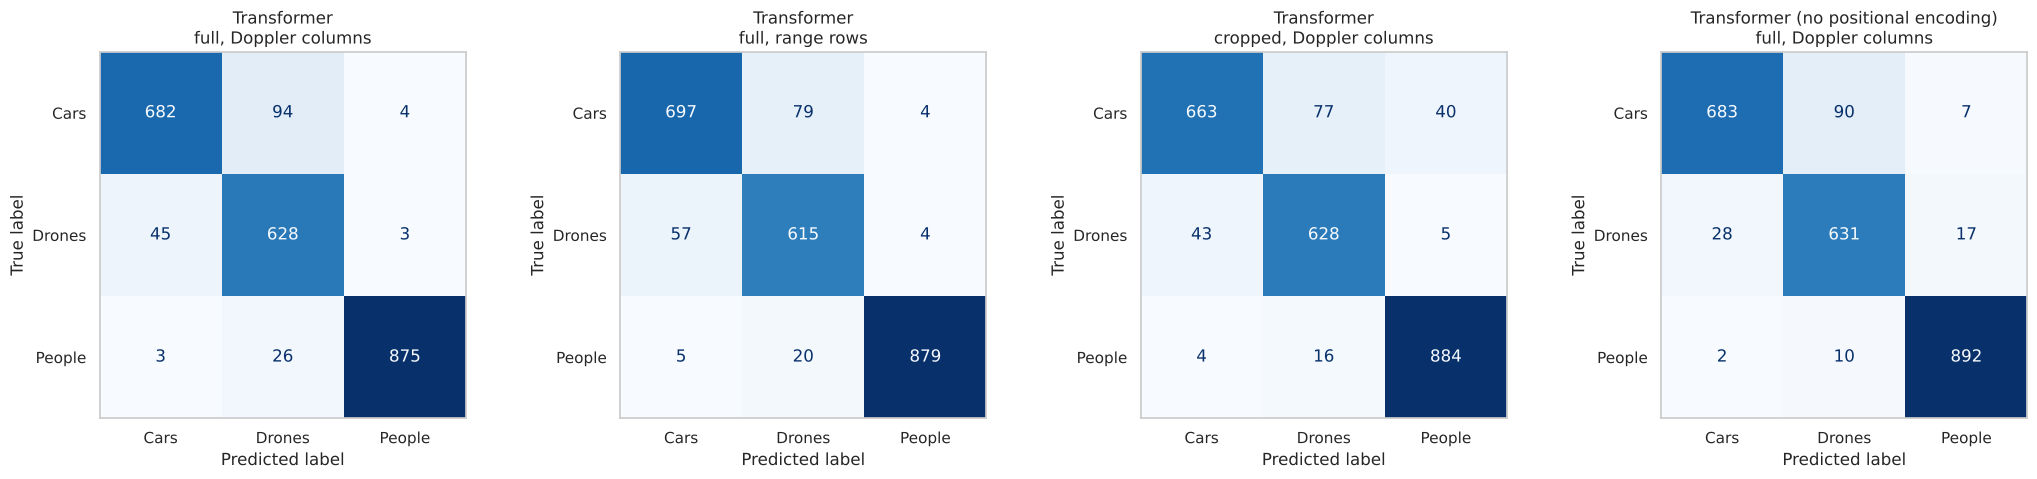

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
for ax, key in zip(axes, keys):
    plot_confusion(y[te], preds[key], CLASSES, f"{key[0]}\n{key[1]}", ax)
plt.tight_layout(); plt.savefig(FIG / "dl_23_transformer_confusion.png", dpi=200); plt.show()

## 6. What does the attention look at?
For the reference Transformer (Doppler columns, full map), we extract the **attention weights of the first block**: for each map, a 61 × 61 matrix per head, where row i tells how much column i "looks at" every other column.

- **Attention received by each Doppler column:** average over heads and over all querying columns. A column that receives a lot of attention is used by many other columns to build their representation.
- **Shortcut test:** share of the attention received by columns **outside** the central region (bins 24–36), for each class and for People with / without a stripe. Uniform attention would give 48/61 ≈ 79%.

*Caveat:* attention weights show where information is gathered, not exactly what drives the final decision (later layers mix everything). They are a useful hint, read together with the full vs cropped results.

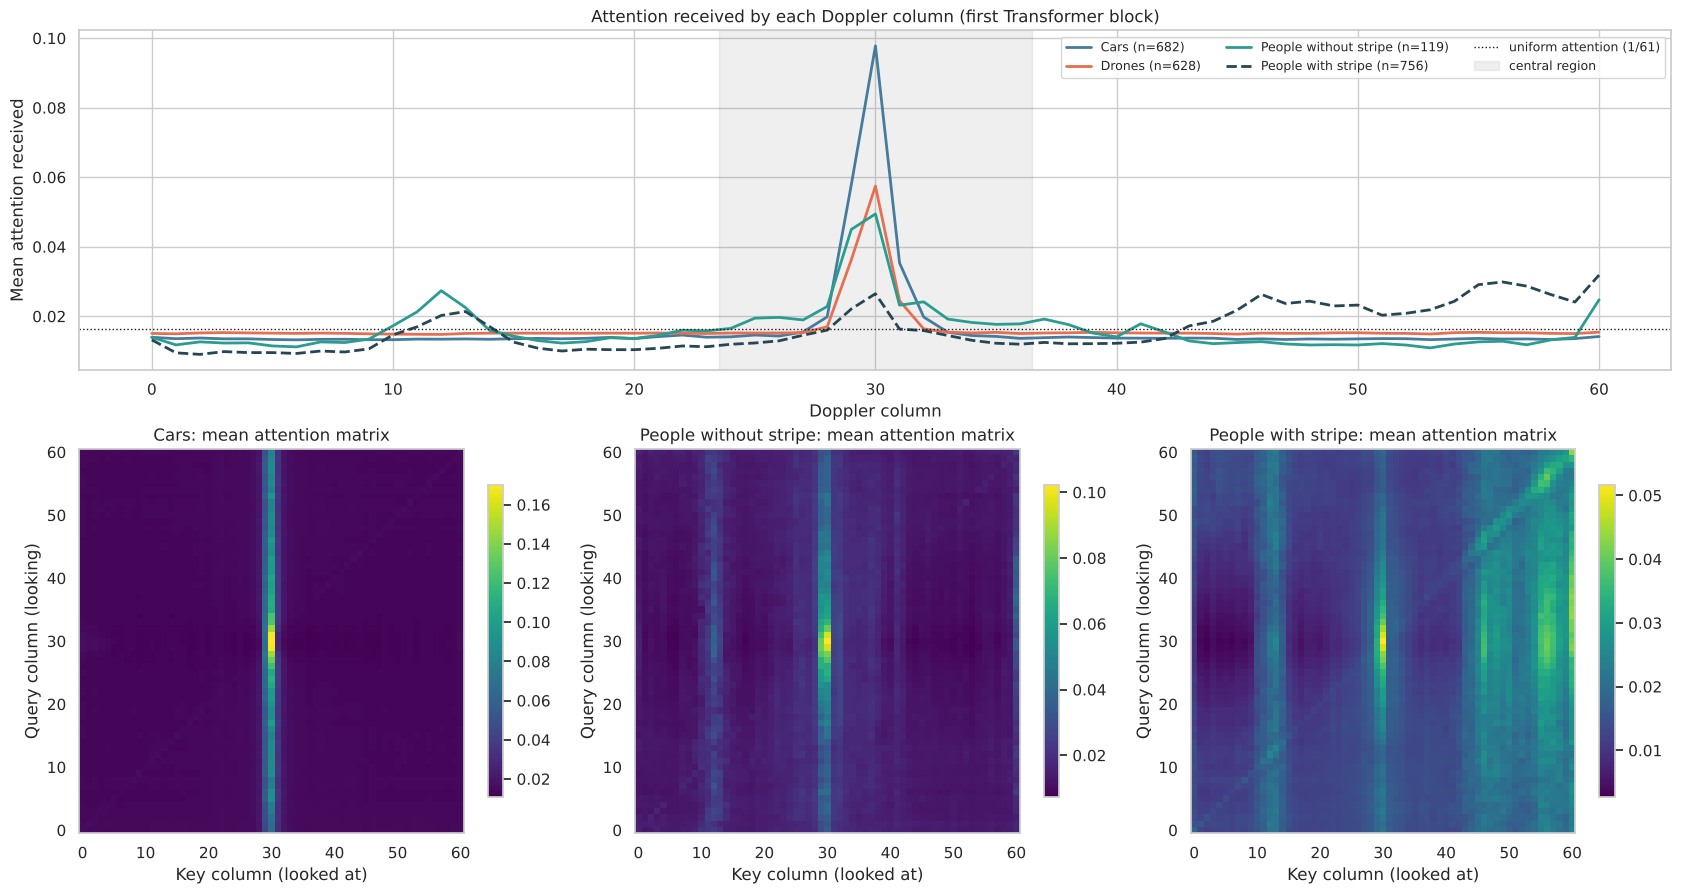

Share of the attention received by Doppler columns OUTSIDE the centre (uniform = 0.787):
Cars                     0.653
Drones                   0.726
People without stripe    0.688
People with stripe       0.800


In [8]:
key = ("Transformer", "full, Doppler columns")
m = models[key]
Xs = TOKENS["full, Doppler columns"]
ok = te[preds[key] == y[te]]
S = m.attention_model.predict(Xs[ok], verbose=0, batch_size=256)       # (n, heads, 61, 61)
received = S.mean(axis=(1, 2))                                          # (n, 61): attention received by each column

noise = np.median(X.reshape(len(X), -1), axis=1)
stripe = ((X.min(axis=1) - noise[:, None])[:, np.r_[0:24, 37:61]] > 10).any(axis=1)
groups = {"Cars": (y[ok] == 0), "Drones": (y[ok] == 1),
          "People without stripe": (y[ok] == 2) & ~stripe[ok], "People with stripe": (y[ok] == 2) & stripe[ok]}
col = {"Cars": "#457b9d", "Drones": "#e76f51", "People without stripe": "#2a9d8f", "People with stripe": "#264653"}

fig = plt.figure(figsize=(17, 9))
gs = fig.add_gridspec(2, 3, height_ratios=[1, 1.15])
ax = fig.add_subplot(gs[0, :])
for g, sel in groups.items():
    ax.plot(np.arange(61), received[sel].mean(0), lw=2, color=col[g], label=f"{g} (n={sel.sum()})",
            ls="--" if g == "People with stripe" else "-")
ax.axhline(1 / 61, color="k", ls=":", lw=1, label="uniform attention (1/61)")
ax.axvspan(CENTER_DOPPLER.start - 0.5, CENTER_DOPPLER.stop - 0.5, color="grey", alpha=0.12, label="central region")
ax.set(xlabel="Doppler column", ylabel="Mean attention received", title="Attention received by each Doppler column (first Transformer block)")
ax.legend(fontsize=9, ncol=3)
for j, g in enumerate(["Cars", "People without stripe", "People with stripe"]):
    a = fig.add_subplot(gs[1, j])
    im = a.imshow(S[groups[g]].mean(axis=(0, 1)), cmap="viridis", origin="lower")
    a.set(title=f"{g}: mean attention matrix", xlabel="Key column (looked at)", ylabel="Query column (looking)")
    a.grid(False); fig.colorbar(im, ax=a, shrink=0.8)
plt.tight_layout(); plt.savefig(FIG / "dl_24_transformer_attention.png", dpi=200); plt.show()

outside = np.r_[0:24, 37:61]
share = pd.Series({g: received[sel][:, outside].sum() / received[sel].sum() for g, sel in groups.items()})
print("Share of the attention received by Doppler columns OUTSIDE the centre (uniform = 0.787):")
print(share.round(3).to_string())

## 7. Conclusions
*(to be written in the report from the outputs above)*